# Collect Fixed Platform Coverage (Towers and Tethered Balloons)

This example demonstrates how to use direct function calls of the low-level TAT-C library to collect the coverage footprints of instruments on fixed surface platforms, such as towers and tethered balloons, using the `SurfacePlatform` schema and the `collect_platform_track`/`compute_platform_track` analysis functions.

A fixed platform combines features of two other TAT-C observing systems. Like a ground-based radar (see the [Collect Radar Coverage](CollectRadarTrack.ipynb) example), it does not move in the Earth-fixed frame, so these functions report one static footprint per platform and instrument rather than a time series. Like a satellite (see the [Collect Orbit and Ground Track](CollectOrbitGroundTrack.ipynb) example), it hosts generic (`Instrument`) or pointed (`PointedInstrument`) instruments, whose views are projected onto a target elevation exactly as a satellite's ground track is.

The platforms in this example are hypothetical, sited around Phoenix, Arizona.

## Tethered Balloon

A `SurfacePlatform` is located by its `latitude`, `longitude`, and ground `elevation`, with its instruments a `height` above the ground (for example, a tower's height or a tethered balloon's altitude above its tether point). Elevations are heights above the WGS 84 ellipsoid, the surface onto which footprints are projected. Around Phoenix, these are about 30 m less than heights above mean sea level (the geoid undulation).

The first platform is a tethered balloon flying 1,000 m above downtown Phoenix, where the ground is about 330 m above mean sea level (300 m above the ellipsoid). It carries two generic instruments, each observing a cone around nadir:

 * `Camera`: a 60 degree field of regard, as for a downward-looking camera.
 * `Horizon`: a 180 degree field of regard, which observes everything below the horizon.

In [1]:
from tatc.schemas import Instrument, SurfacePlatform

balloon = SurfacePlatform(
    name="Balloon",
    latitude=33.4484,
    longitude=-112.0740,
    elevation=300,
    height=1000,
    instruments=[
        Instrument(name="Camera", field_of_regard=60),
        Instrument(name="Horizon", field_of_regard=180),
    ],
)

The `collect_platform_track` method computes each instrument's footprint. By default it projects onto the platform's ground elevation; pass `elevation` to use another target elevation, either below the instruments (looking down) or above them (looking up, see [Looking Up](#Looking-Up)). As in `collect_ground_track`, `instrument_index` selects one instrument of each platform (the first by default), or `None` selects all of them. Results are formatted as a flat GeoDataFrame, similar to a regular pandas DataFrame with a geospatial column labeled `geometry`. Other columns:
 * `platform`: platform name
 * `instrument`: instrument name
 * `elevation`: target elevation (m) onto which the footprint is projected

In [2]:
from tatc.analysis import collect_platform_track

results = collect_platform_track(balloon, instrument_index=None)
display(results)

,platform,instrument,elevation,geometry
0,Balloon,Camera,300.0,"POLYGON Z ((-112.08021 33.4484 300, -112.08008..."
1,Balloon,Horizon,300.0,"POLYGON Z ((-113.2892 33.44245 300, -113.26703..."


To measure footprints, it helps to transform them into a local azimuthal equidistant projection centered on the platform, in which coordinates are distances (m) east and north of it. From 1,000 m, the camera's footprint is a disk of radius 1,000 tan(30°) = 577 m. The horizon instrument sees out to the horizon, about √(2Rh) ≈ 113 km away for a height h and Earth radius R. Rays that miss the target surface (looking above the horizon) are projected onto the horizon, as for a satellite's view of the Earth's limb.

In [3]:
import numpy as np


def local_crs(platform):
    """Azimuthal equidistant projection (m) centered on a platform."""
    return f"+proj=aeqd +lat_0={platform.latitude} +lon_0={platform.longitude} +datum=WGS84 +units=m"


def mean_radius(track, platform):
    """Mean distance (m) from a platform to the boundary of each footprint."""
    local = track.to_crs(local_crs(platform))
    return local.geometry.apply(
        lambda g: np.hypot(*np.array(g.exterior.coords)[:, :2].T).mean()
    )


summary = results[["platform", "instrument", "elevation"]].copy()
summary["radius (km)"] = mean_radius(results, balloon) / 1e3
summary["area (km2)"] = results.to_crs(local_crs(balloon)).area / 1e6
display(summary.round(3))

,platform,instrument,elevation,radius (km),area (km2)
0,Balloon,Camera,300.0,0.577,1.040
1,Balloon,Horizon,300.0,112.863,39741.534


The footprints can be plotted on a map and, for the small camera footprint, in local coordinates.

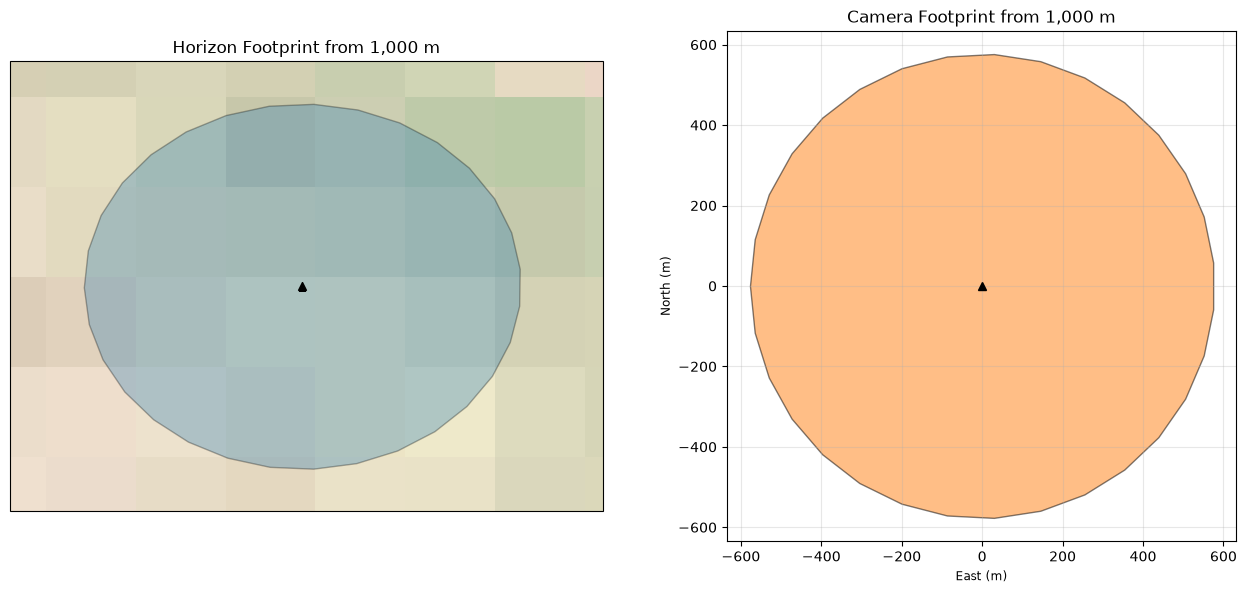

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(13, 6))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
results[results.instrument == "Horizon"].plot(
    facecolor="tab:blue", edgecolor="k", alpha=0.3, ax=ax, transform=ccrs.PlateCarree()
)
ax.plot(balloon.longitude, balloon.latitude, "k^", transform=ccrs.PlateCarree())
ax.stock_img()
ax.add_feature(cfeature.STATES, edgecolor="gray")
ax.set_extent([-113.7, -110.4, 32.2, 34.7], crs=ccrs.PlateCarree())
ax.set_title("Horizon Footprint from 1,000 m")

ax = fig.add_subplot(1, 2, 2)
results[results.instrument == "Camera"].to_crs(local_crs(balloon)).plot(
    facecolor="tab:orange", edgecolor="k", alpha=0.5, ax=ax
)
ax.plot(0, 0, "k^")
ax.set(
    xlabel="East (m)",
    ylabel="North (m)",
    title="Camera Footprint from 1,000 m",
    aspect="equal",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Platform Height

A platform's height governs how much it can see. The radius of a narrow view's footprint grows in proportion to height, while the distance to the horizon grows only with its square root. Collecting the balloon's footprints at several heights shows both trends: the camera footprint's radius doubles from 1,000 m to 2,000 m, while the horizon moves out by only about 40%.

In [5]:
heights = [100, 250, 500, 1000, 2000]
balloons = [
    balloon.model_copy(update={"name": f"{height} m", "height": height})
    for height in heights
]
by_height = collect_platform_track(balloons, instrument_index=None)
by_height["radius (km)"] = mean_radius(by_height, balloon) / 1e3
display(
    by_height.pivot(index="platform", columns="instrument", values="radius (km)")
    .loc[[balloon.name for balloon in balloons]]
    .round(3)
)

instrument,Camera,Horizon
platform,,
100 m,0.058,35.694
250 m,0.144,56.434
500 m,0.289,79.809
1000 m,0.577,112.863
2000 m,1.155,159.602


## Tower with Pointed Instruments

A `PointedInstrument` rotates its view away from nadir by a roll angle (positive to the left) and then a pitch angle (positive forward). On a satellite, left and forward are relative to its direction of motion; on a platform, they are relative to its `heading`, the azimuth (clockwise from north) of its forward direction.

The next platform is a 30 m tower in Tempe, Arizona, where the ground is about 350 m above mean sea level (320 m above the ellipsoid). Its heading is north (the default), and it hosts three pointed instruments:

 * `North camera`: a rectangular frame camera with a 60 degree horizontal and 40 degree vertical field of view. A 60 degree forward pitch points it north, 30 degrees below horizontal, so it views from 40 to 80 degrees from nadir. Pitching about the cross-track axis keeps the horizontal field of view across track.
 * `West camera`: the same camera rolled 60 degrees to the left (west). Rolling about the along-track axis turns the cross-track field of view vertical, so its fields of view are swapped (40 degrees across track and 60 degrees along track).
 * `Scanner`: a cross-track scanner (`ViewGeometry.SCAN`) sweeping 60 degrees to either side of nadir (east and west), with a 2 degree along-track field of view, as for a scanning radiometer.

In [6]:
from tatc.schemas import PointedInstrument
from tatc.utils import ViewGeometry

tower = SurfacePlatform(
    name="Tower",
    latitude=33.4242,
    longitude=-111.9281,
    elevation=320,
    height=30,
    instruments=[
        PointedInstrument(
            name="North camera",
            cross_track_field_of_view=60,
            along_track_field_of_view=40,
            pitch_angle=60,
            is_rectangular=True,
        ),
        PointedInstrument(
            name="West camera",
            cross_track_field_of_view=40,
            along_track_field_of_view=60,
            roll_angle=60,
            is_rectangular=True,
        ),
        PointedInstrument(
            name="Scanner",
            cross_track_field_of_view=120,
            along_track_field_of_view=2,
            view_geometry=ViewGeometry.SCAN,
            is_rectangular=True,
        ),
    ],
)

tower_results = collect_platform_track(tower, instrument_index=None)
display(tower_results)

,platform,instrument,elevation,geometry
0,Tower,North camera,320.0,"POLYGON Z ((-111.92833 33.42443 320, -111.9283..."
1,Tower,West camera,320.0,"POLYGON Z ((-111.92993 33.42335 320, -111.9299..."
2,Tower,Scanner,320.0,"POLYGON Z ((-111.92866 33.42419 320, -111.9286..."


In local coordinates, each camera's footprint is a trapezoid that widens with distance. Its near edge is 30 tan(40°) = 25 m from the tower, and its far edge 30 tan(80°) = 170 m. The scanner's footprint is a strip 30 tan(60°) = 52 m to either side of the tower, widening away from nadir because its along-track field of view is a constant angle.

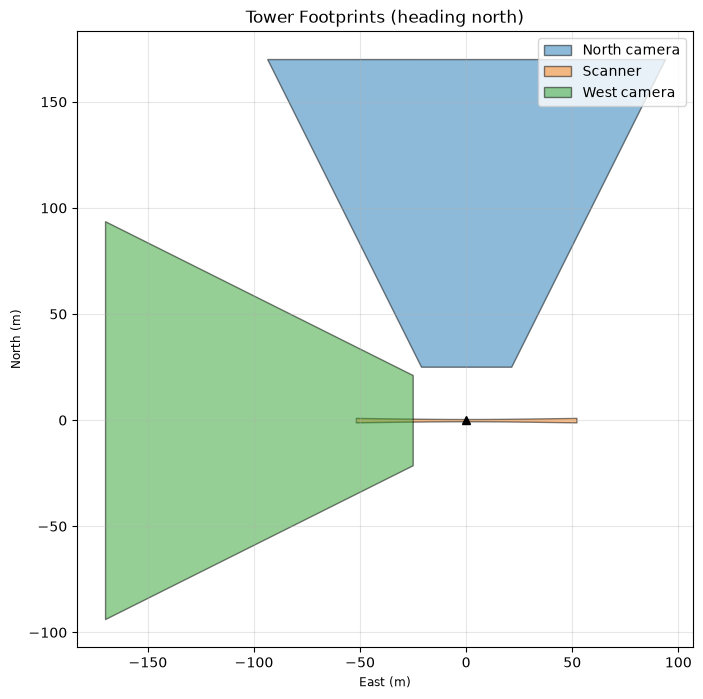

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
tower_results.to_crs(local_crs(tower)).plot(
    column="instrument", cmap="tab10", edgecolor="k", alpha=0.5, legend=True, ax=ax
)
ax.plot(0, 0, "k^")
ax.set(
    xlabel="East (m)",
    ylabel="North (m)",
    title="Tower Footprints (heading north)",
    aspect="equal",
)
ax.grid(True, alpha=0.3)
plt.show()

### Pixels

A `PointedInstrument` with `cross_track_pixels` and `along_track_pixels` defines a pixel array, and its `compute_footprint_pixel_array` method projects the pixel centers from the platform's track (`SurfacePlatform.get_track`). Seen at a slant from a tower, ground pixels stretch with distance. Here the north camera has 12 by 8 pixels. Along its central columns, rows are about 5 m apart near the tower and about 40 m apart at the far edge, and rows bow away from the tower at their ends, where off-axis pixels look farther from nadir.

row distances (m): [ 27.5  32.7  39.1  47.1  57.6  72.4  95.2 135.4]
row spacing (m): [ 5.3  6.4  8.  10.5 14.8 22.8 40.3]


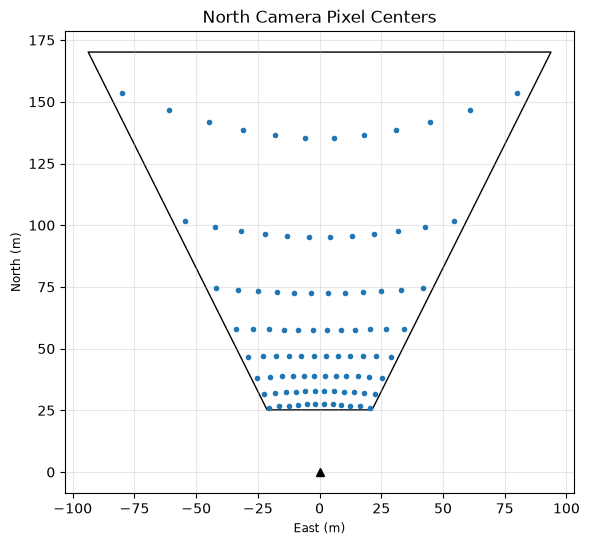

In [8]:
import geopandas as gpd

pixel_camera = tower.instruments[0].model_copy(
    update={"cross_track_pixels": 12, "along_track_pixels": 8}
)
pixels = pixel_camera.compute_footprint_pixel_array(
    tower.get_track(), elevation=tower.elevation
)[0]
pixels_local = gpd.GeoSeries([pixels], crs="EPSG:4326").to_crs(local_crs(tower)).iloc[0]

# pixel centers by cross-track (right to left) and along-track (fore to aft) index
centers = np.array([(p.x, p.y) for p in pixels_local.geoms]).reshape(12, 8, 2)
# distances (north) of the rows, averaged over the two central columns
rows = np.sort(centers[5:7, :, 1].mean(axis=0))
print("row distances (m):", np.round(rows, 1))
print("row spacing (m):", np.round(np.diff(rows), 1))

fig, ax = plt.subplots(figsize=(8, 6))
tower_results[tower_results.instrument == "North camera"].to_crs(local_crs(tower)).plot(
    facecolor="none", edgecolor="k", ax=ax
)
ax.plot(
    [p.x for p in pixels_local.geoms],
    [p.y for p in pixels_local.geoms],
    ".",
    color="tab:blue",
)
ax.plot(0, 0, "k^")
ax.set(
    xlabel="East (m)",
    ylabel="North (m)",
    title="North Camera Pixel Centers",
    aspect="equal",
)
ax.grid(True, alpha=0.3)
plt.show()

## Observation Conditions

Although footprints are static, an instrument's observation conditions can still vary with time, just as for a satellite. `SurfacePlatform.get_track` accepts times, and instrument methods such as `is_valid_observation` evaluate its requirements at each one. For example, the north camera may require the sun at least 10 degrees above the horizon at the center of its footprint (`min_target_solar_elevation`). Evaluated every 10 minutes on 16 October 2026, it observes from about 7:30 to 16:50 local time (Arizona does not observe daylight saving time, so local time is UTC-7).

first valid: 2026-10-16 07:30:00-07:00
last valid: 2026-10-16 16:50:00-07:00
valid fraction of the day: 39.6%


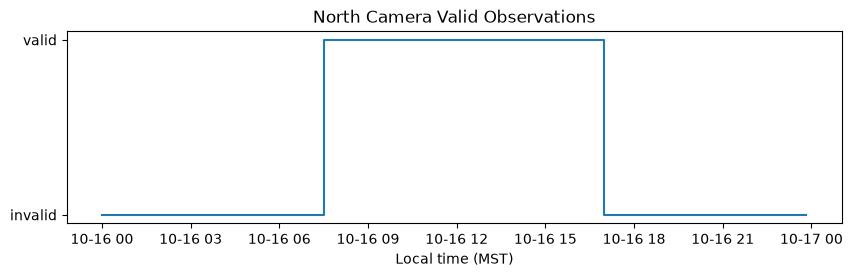

In [9]:
from datetime import datetime, timedelta, timezone

import pandas as pd

times = [
    datetime(2026, 10, 16, 7, tzinfo=timezone.utc) + timedelta(minutes=10 * i)
    for i in range(144)
]
camera = tower.instruments[0].model_copy(update={"min_target_solar_elevation": 10})
track = tower.get_track(times)
center = camera.compute_footprint_center(track, elevation=tower.elevation)
valid = pd.Series(
    camera.is_valid_observation(track, center),
    index=pd.DatetimeIndex(times).tz_convert("America/Phoenix"),
)
print("first valid:", valid[valid].index[0])
print("last valid:", valid[valid].index[-1])
print(f"valid fraction of the day: {valid.mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.step(valid.index.tz_localize(None), valid.astype(int), where="post")
ax.set(
    yticks=[0, 1],
    yticklabels=["invalid", "valid"],
    xlabel="Local time (MST)",
    title="North Camera Valid Observations",
)
plt.show()

## Network Coverage

The `compute_platform_track` method dissolves the footprints of several platforms into a single composite geometry (for example, a network coverage map), optionally clipped to a mask. Here, a network of five tethered balloons flies 1,000 m above cities across the Phoenix metropolitan area. Each carries a downward-looking instrument with a 170 degree field of regard, which reaches to 5 degrees below the horizon, a radius of about 1,000 tan(85°) ≈ 11.4 km. Ground elevations are approximate. The mask clips the composite to the area south of 33.55°N.

composite area: 1575 km2
masked composite area: 1323 km2


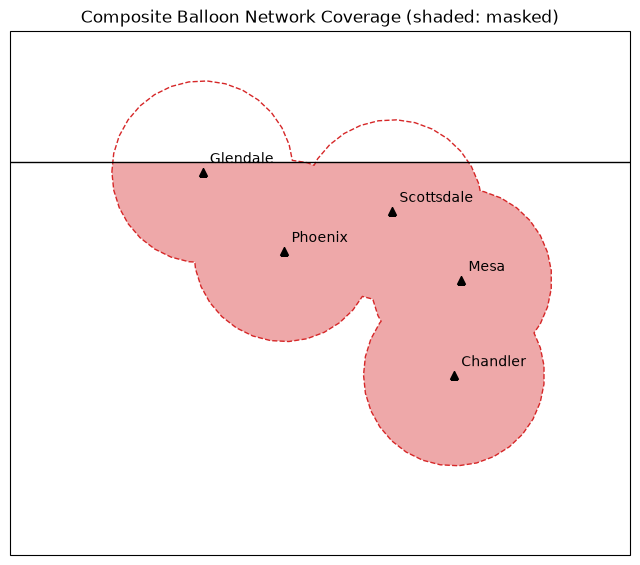

In [10]:
from shapely.geometry import box

from tatc.analysis import compute_platform_track

sites = {
    "Phoenix": (33.4484, -112.0740, 300),
    "Glendale": (33.5387, -112.1860, 320),
    "Scottsdale": (33.4942, -111.9261, 350),
    "Mesa": (33.4152, -111.8315, 350),
    "Chandler": (33.3062, -111.8413, 340),
}
network = [
    SurfacePlatform(
        name=name,
        latitude=latitude,
        longitude=longitude,
        elevation=elevation,
        height=1000,
        instruments=[Instrument(name="Imager", field_of_regard=170)],
    )
    for name, (latitude, longitude, elevation) in sites.items()
]
mask = box(-112.5, 33.0, -111.5, 33.55)

composite = compute_platform_track(network)
composite_masked = compute_platform_track(network, mask=mask)
print(
    f"composite area: {composite.to_crs(local_crs(network[0])).area.iloc[0] / 1e6:.0f} km2"
)
print(
    f"masked composite area: {composite_masked.to_crs(local_crs(network[0])).area.iloc[0] / 1e6:.0f} km2"
)

fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={"projection": ccrs.PlateCarree()})
composite.plot(
    facecolor="none", edgecolor="tab:red", ls="--", ax=ax, transform=ccrs.PlateCarree()
)
composite_masked.plot(
    facecolor="tab:red",
    edgecolor="none",
    alpha=0.4,
    ax=ax,
    transform=ccrs.PlateCarree(),
)
ax.plot(*mask.exterior.xy, color="k", lw=1, transform=ccrs.PlateCarree())
for platform in network:
    ax.plot(platform.longitude, platform.latitude, "k^", transform=ccrs.PlateCarree())
    ax.text(
        platform.longitude + 0.01,
        platform.latitude + 0.01,
        platform.name,
        transform=ccrs.PlateCarree(),
    )
ax.add_feature(cfeature.STATES, edgecolor="gray")
ax.set_extent([-112.45, -111.6, 33.1, 33.7], crs=ccrs.PlateCarree())
ax.set_title("Composite Balloon Network Coverage (shaded: masked)")
plt.show()

## Looking Up

Instruments can also look up at a target elevation above the platform, for example from a tower to the base of a cloud layer. A roll angle of 180 degrees turns a `PointedInstrument`'s view from nadir to zenith (straight up). Here the tower in Tempe hosts two sky cameras viewing a cloud base 2,000 m above the ground (2,320 m above the ellipsoid):

 * `Sky camera`: an all-sky imager with a 160 degree circular field of view about zenith, which reaches down to 10 degrees above the horizon.
 * `West sky camera`: a rectangular frame camera with a 40 degree field of view, rolled 90 degrees to the left (west) so that it looks horizontally, from 20 degrees below to 20 degrees above the horizon.

In [11]:
sky_tower = tower.model_copy(
    update={
        "instruments": [
            PointedInstrument(
                name="Sky camera",
                cross_track_field_of_view=160,
                along_track_field_of_view=160,
                roll_angle=180,
            ),
            PointedInstrument(
                name="West sky camera",
                cross_track_field_of_view=40,
                along_track_field_of_view=40,
                roll_angle=90,
                is_rectangular=True,
            ),
        ]
    }
)
cloud_base = tower.elevation + 2000
sky_results = collect_platform_track(
    sky_tower, instrument_index=None, elevation=cloud_base
)


def distance_range(track, platform):
    """Minimum and maximum distances (m) from a platform to the boundary of each footprint."""
    local = track.to_crs(local_crs(platform))
    distances = local.geometry.apply(
        lambda g: np.hypot(*np.array(g.exterior.coords)[:, :2].T)
    )
    return distances.apply(np.min), distances.apply(np.max)


sky_summary = sky_results[["platform", "instrument", "elevation"]].copy()
sky_summary["near (km)"], sky_summary["far (km)"] = (
    d / 1e3 for d in distance_range(sky_results, sky_tower)
)
sky_summary["area (km2)"] = sky_results.to_crs(local_crs(sky_tower)).area / 1e6
display(sky_summary.round(3))

,platform,instrument,elevation,near (km),far (km),area (km2)
0,Tower,Sky camera,2320.0,11.057,11.114,385.383
1,Tower,West sky camera,2320.0,5.404,179.355,11215.478


The all-sky imager's footprint is a disk of radius about 1,970 tan(80°) ≈ 11.2 km, or 11.1 km because the cloud base curves away below its lines of sight. The west sky camera's upper edge, 20 degrees above the horizon, reaches the cloud base 1,970 / tan(20°) ≈ 5.4 km away. Its lower half looks below the horizon, where the ground blocks its view, so its footprint is clipped to the horizon: the lines of sight tangent to the ground, which graze the ground about √(2R × 30 m) ≈ 20 km away and reach the cloud base about √(2R × 2,000 m) ≈ 160 km beyond. The footprint's far edge, an arc about 179 km away spanning the camera's 40 degree width, bounds the part of the cloud base visible over the horizon. (A view entirely below the horizon, such as a downward-looking camera, has an empty footprint.)

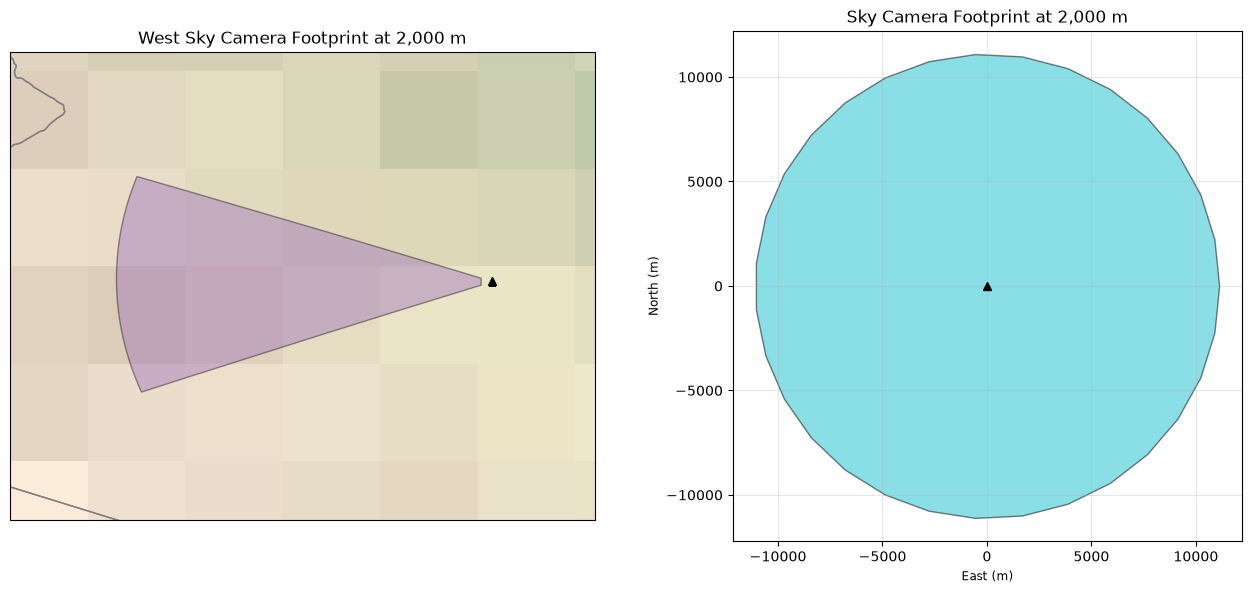

In [12]:
fig = plt.figure(figsize=(13, 6))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
sky_results[sky_results.instrument == "West sky camera"].plot(
    facecolor="tab:purple",
    edgecolor="k",
    alpha=0.4,
    ax=ax,
    transform=ccrs.PlateCarree(),
)
ax.plot(sky_tower.longitude, sky_tower.latitude, "k^", transform=ccrs.PlateCarree())
ax.stock_img()
ax.add_feature(cfeature.STATES, edgecolor="gray")
ax.set_extent([-114.4, -111.4, 32.2, 34.6], crs=ccrs.PlateCarree())
ax.set_title("West Sky Camera Footprint at 2,000 m")

ax = fig.add_subplot(1, 2, 2)
sky_results[sky_results.instrument == "Sky camera"].to_crs(local_crs(sky_tower)).plot(
    facecolor="tab:cyan", edgecolor="k", alpha=0.5, ax=ax
)
ax.plot(0, 0, "k^")
ax.set(
    xlabel="East (m)",
    ylabel="North (m)",
    title="Sky Camera Footprint at 2,000 m",
    aspect="equal",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

`collect_platform_track` treats the ground at a platform's elevation as blocking views toward a target above its instruments. When calling instrument methods directly, such as `compute_footprint`, `compute_footprint_center`, or `compute_footprint_pixel_array`, pass `ground_elevation=platform.elevation` for the same behavior (by default, the ground is the WGS 84 ellipsoid). Here the all-sky imager has 9 by 9 pixels. Along its central column, pixels look 0, 17.8, 35.6, 53.3, and 71.1 degrees from zenith, so their centers on the cloud base spread out toward the horizon, about 1,970 tan(71.1°) ≈ 5.8 km away at the edge.

In [13]:
pixel_sky_camera = sky_tower.instruments[0].model_copy(
    update={"cross_track_pixels": 9, "along_track_pixels": 9}
)
sky_pixels = pixel_sky_camera.compute_footprint_pixel_array(
    sky_tower.get_track(), elevation=cloud_base, ground_elevation=sky_tower.elevation
)[0]
sky_pixels_local = (
    gpd.GeoSeries([sky_pixels], crs="EPSG:4326").to_crs(local_crs(sky_tower)).iloc[0]
)

# pixel centers by cross-track and along-track index
sky_centers = np.array([(p.x, p.y) for p in sky_pixels_local.geoms]).reshape(9, 9, 2)
# offsets (north) of the pixels in the central column
print("central column offsets (km):", np.round(np.sort(sky_centers[4, :, 1]) / 1e3, 2))
print("pixel elevations (m):", sorted({round(p.z) for p in sky_pixels.geoms}))

central column offsets (km): [-5.75 -2.64 -1.41 -0.63  0.    0.63  1.41  2.64  5.75]
pixel elevations (m): [2320]


### Terrain Mask

The ground at a platform's elevation is an idealized horizon: real terrain can block low lines of sight in some directions. A `TerrainMask`, as for a `RadarStation` (see the [Collect Radar Coverage](CollectRadarTrack.ipynb) example), gives the minimum usable elevation angle at each azimuth, and a platform's `terrain_mask` clips footprints toward a target above its instruments to the region visible over it (`SurfacePlatform.compute_visible_region`). It does not apply to targets below the instruments.

The `tatc.preprocess` module (installed via `pip install tatc[preprocess]`) derives a terrain mask from a digital elevation model (DEM). `compute_terrain_mask_for_platform` places the instruments a platform's `height` above the DEM's ground at its location (in the DEM's vertical datum, mean sea level for the [Copernicus DEM GLO-30](https://registry.opendata.aws/copernicus-dem/)) and, by default, uses straight lines of sight (`effective_earth_radius_factor=1`) without the radio refraction assumed for radars, matching the geometry of the platform's footprints. Here the mask samples every 1 degree of azimuth out to 100 km. Fetching the DEM over the network takes about a minute, so the mask is saved to a file for reuse.

In [14]:
import json

from tatc.schemas import TerrainMask

TERRAIN_MASK_PATH = "tempe_tower_terrain_mask.json"
REGENERATE_TERRAIN_MASK = False  # set True to re-derive from the DEM over the network

if REGENERATE_TERRAIN_MASK:
    from tatc.preprocess import (
        compute_terrain_mask_for_platform,
        get_copernicus_dem_tile_urls,
    )

    dem_urls = get_copernicus_dem_tile_urls(
        sky_tower.longitude, sky_tower.latitude, radius=100000
    )
    sky_tower.terrain_mask = compute_terrain_mask_for_platform(
        dem_urls, sky_tower, search_radius=100000
    )
    with open(TERRAIN_MASK_PATH, "w", encoding="utf-8") as f:
        json.dump({sky_tower.name: sky_tower.terrain_mask.model_dump()}, f, indent=2)
else:
    with open(TERRAIN_MASK_PATH, encoding="utf-8") as f:
        sky_tower.terrain_mask = TerrainMask(**json.load(f)[sky_tower.name])

open_sky = sky_tower.model_copy(update={"terrain_mask": None})
visible = gpd.GeoSeries(
    [
        open_sky.compute_visible_region(cloud_base),
        sky_tower.compute_visible_region(cloud_base),
    ],
    index=["ground horizon", "terrain mask"],
    crs="EPSG:4326",
)
masked_results = collect_platform_track(
    sky_tower, instrument_index=None, elevation=cloud_base
)

angles = sky_tower.terrain_mask.min_elevation_angle
print(f"terrain mask: {min(angles):.2f} to {max(angles):.2f} degrees")
print(
    "visible cloud base (km2):",
    (visible.to_crs(local_crs(sky_tower)).area / 1e6).round(0).to_dict(),
)
masked_summary = masked_results[["instrument"]].copy()
masked_summary["area without mask (km2)"] = (
    sky_results.to_crs(local_crs(sky_tower)).area / 1e6
)
masked_summary["area with mask (km2)"] = (
    masked_results.to_crs(local_crs(sky_tower)).area / 1e6
)
display(masked_summary.round(1))

terrain mask: -0.29 to 2.00 degrees
visible cloud base (km2): {'ground horizon': 100818.0, 'terrain mask': 50977.0}


,instrument,area without mask (km2),area with mask (km2)
0,Sky camera,385.4,385.4
1,West sky camera,11215.5,8424.1


Mountains around the Phoenix valley rise up to about 2 degrees above the horizon, so the terrain mask halves the area of the cloud base visible from the tower, bounding it 50 to 180 km away rather than at the horizon of the ground, about 179 km away in every direction. The all-sky imager, which reaches down to 10 degrees above the horizon, is unaffected, while the far edge of the west sky camera's footprint now follows the terrain to the west.

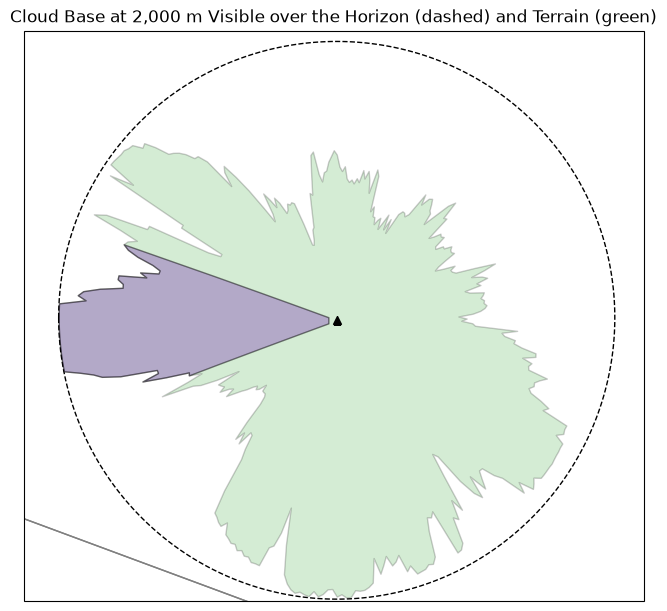

In [15]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
visible[["ground horizon"]].plot(
    facecolor="none", edgecolor="k", ls="--", ax=ax, transform=ccrs.PlateCarree()
)
visible[["terrain mask"]].plot(
    facecolor="tab:green", edgecolor="k", alpha=0.2, ax=ax, transform=ccrs.PlateCarree()
)
masked_results[masked_results.instrument == "West sky camera"].plot(
    facecolor="tab:purple",
    edgecolor="k",
    alpha=0.5,
    ax=ax,
    transform=ccrs.PlateCarree(),
)
ax.plot(sky_tower.longitude, sky_tower.latitude, "k^", transform=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, edgecolor="gray")
ax.set_extent([-114.1, -109.8, 31.8, 35.1], crs=ccrs.PlateCarree())
ax.set_title(
    "Cloud Base at 2,000 m Visible over the Horizon (dashed) and Terrain (green)"
)
plt.show()

## Limitations

Footprints are projected onto a single target elevation, either below the instruments (the same geometry as a satellite looking down at the Earth) or above them; `collect_platform_track` raises a `ValueError` for a target elevation equal to a platform's instruments. Toward a target below the instruments, footprints do not account for terrain or obstructions; toward a target above them, the ground at the platform's elevation and an optional terrain mask (one blocking angle per azimuth) block views. Footprints do not account for atmospheric refraction, and `ConicalInstrument` views, which depend on a satellite's motion, are not supported on platforms.